# Unsupervised Learning
## Segmenting Shopping Mall Customers

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
# Problem 1 - Preprocessing
# Read in the data
customers = pd.read_csv('mallcustomers.csv')

# Previewing the dataset
customers

,CustomerID,Gender,Age,Income,SpendingScore
0,1,Male,19,"15,000 USD",39
1,2,Male,21,"15,000 USD",81
2,3,Female,20,"16,000 USD",6
3,4,Female,23,"16,000 USD",77
4,5,Female,31,"17,000 USD",40
...,...,...,...,...,...
195,196,Female,35,"120,000 USD",79
196,197,Female,45,"126,000 USD",28
197,198,Male,32,"126,000 USD",74
198,199,Male,32,"137,000 USD",18


In [3]:
# Observing variables' data types and checking for null counts
# Note that two 'string' variables (identified as 'object') are detected, while no 'null' items are detected
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     200 non-null    int64 
 1   Gender         200 non-null    object
 2   Age            200 non-null    int64 
 3   Income         200 non-null    object
 4   SpendingScore  200 non-null    int64 
dtypes: int64(3), object(2)
memory usage: 7.9+ KB


In [4]:
# Removing the ','s and 'USD' from the 'Income' variable
customers['Income'] = customers['Income'].str.replace(',', '', regex=False).str.replace('USD', '', regex=False)

# Verifying the ','s and 'USD' have been removed from the dataset
customers

,CustomerID,Gender,Age,Income,SpendingScore
0,1,Male,19,15000,39
1,2,Male,21,15000,81
2,3,Female,20,16000,6
3,4,Female,23,16000,77
4,5,Female,31,17000,40
...,...,...,...,...,...
195,196,Female,35,120000,79
196,197,Female,45,126000,28
197,198,Male,32,126000,74
198,199,Male,32,137000,18


In [5]:
# Converting 'Income' to integer data type
customers['Income'] = customers['Income'].astype(int)

In [6]:
# Verifying the data type change to integer
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     200 non-null    int64 
 1   Gender         200 non-null    object
 2   Age            200 non-null    int64 
 3   Income         200 non-null    int64 
 4   SpendingScore  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [7]:
# Problem 2 - Preprocessing
# Dropping the CustomerID column
customers_edit = customers.drop(columns=['CustomerID'])

# Verifying the column has been dropped
customers_edit

,Gender,Age,Income,SpendingScore
0,Male,19,15000,39
1,Male,21,15000,81
2,Female,20,16000,6
3,Female,23,16000,77
4,Female,31,17000,40
...,...,...,...,...
195,Female,35,120000,79
196,Female,45,126000,28
197,Male,32,126000,74
198,Male,32,137000,18


In [8]:
# Problem 3 - Preprocessing
# Running summary statistics on 'Income' and 'SpendingScore'
customers_edit[['Income','SpendingScore']].describe().round(2)

,Income,SpendingScore
count,200.00,200.00
mean,60560.00,50.20
std,26264.72,25.82
min,15000.00,1.00
25%,41500.00,34.75
50%,61500.00,50.00
75%,78000.00,73.00
max,137000.00,99.00


In [9]:
# Applying z-score normalization to 'Income' and 'SpendingScore'
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
customers_edit[['Income_scaled','SpendingScore_scaled']]= scaler.fit_transform(customers_edit[['Income','SpendingScore']])

In [10]:
# Reviewing the scaled data
# Original data remains intact in the original 'customers' dataframe
customers_edit

,Gender,Age,Income,SpendingScore,Income_scaled,SpendingScore_scaled
0,Male,19,15000,39,-1.738999,-0.434801
1,Male,21,15000,81,-1.738999,1.195704
2,Female,20,16000,6,-1.700830,-1.715913
3,Female,23,16000,77,-1.700830,1.040418
4,Female,31,17000,40,-1.662660,-0.395980
...,...,...,...,...,...,...
195,Female,35,120000,79,2.268791,1.118061
196,Female,45,126000,28,2.497807,-0.861839
197,Male,32,126000,74,2.497807,0.923953
198,Male,32,137000,18,2.917671,-1.250054


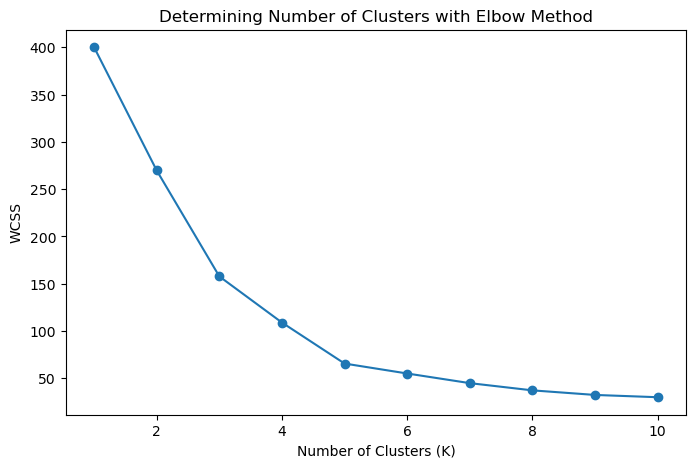

In [11]:
# Problem 4 - Data Clustering
# Filtering warnings for cleaner outputs
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# Using the Elbow Method to determine the optimal number of clusters
X = customers_edit[['Income_scaled', 'SpendingScore_scaled']]
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)  

# Plotting the Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='-')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Determining Number of Clusters with Elbow Method')
plt.show()

In [12]:
# Applying k-means to the data
kmeans_customers = KMeans(n_clusters=5, random_state=42, n_init=10)

# Fitting the KMeans model to the scaled dataset
# Adding Clusters to the database
customers_edit['Cluster'] = kmeans_customers.fit_predict(X)

In [13]:
# Viewing the results
customers_edit

,Gender,Age,Income,SpendingScore,Income_scaled,SpendingScore_scaled,Cluster
0,Male,19,15000,39,-1.738999,-0.434801,4
1,Male,21,15000,81,-1.738999,1.195704,2
2,Female,20,16000,6,-1.700830,-1.715913,4
3,Female,23,16000,77,-1.700830,1.040418,2
4,Female,31,17000,40,-1.662660,-0.395980,4
...,...,...,...,...,...,...,...
195,Female,35,120000,79,2.268791,1.118061,1
196,Female,45,126000,28,2.497807,-0.861839,3
197,Male,32,126000,74,2.497807,0.923953,1
198,Male,32,137000,18,2.917671,-1.250054,3


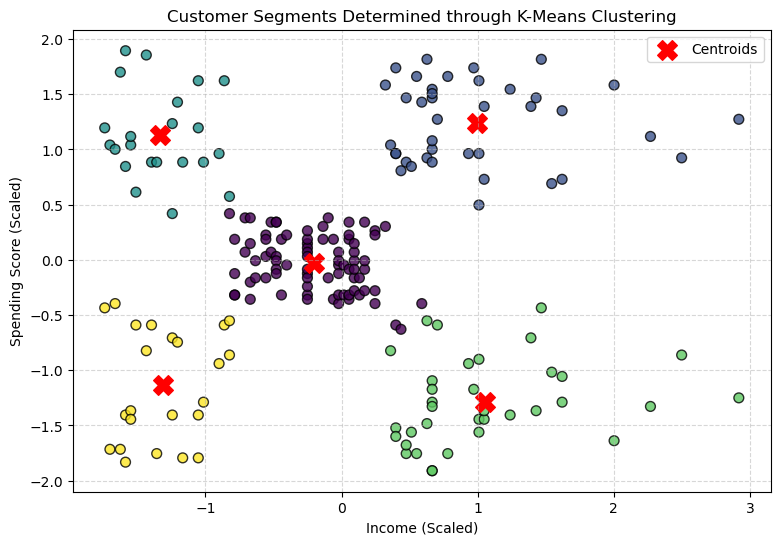

In [14]:
# Visualizing the results
# Plotting 'Income' and 'SpendingScore' in a Scatter Plot
plt.figure(figsize=(9, 6))
plt.scatter(
    customers_edit['Income_scaled'], 
    customers_edit['SpendingScore_scaled'], 
    c=customers_edit['Cluster'], 
    cmap='viridis', 
    s=50, 
    alpha=0.8,
    edgecolors='k'
)

#Plotting the centroids 
centroids = kmeans_customers.cluster_centers_
plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    c='red', 
    marker='X', 
    s=200, 
    label='Centroids'
)

# Labeling the plot
plt.xlabel('Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.title('Customer Segments Determined through K-Means Clustering')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

In [15]:
# Printing centroid coordinates to identify clusters
centroid_df = pd.DataFrame(kmeans_customers.cluster_centers_, columns=['Income_scaled', 'Spending_scaled'])
print(centroid_df)

   Income_scaled  Spending_scaled
0      -0.200913        -0.026456
1       0.991583         1.239503
2      -1.329545         1.132178
3       1.055003        -1.284439
4      -1.307519        -1.136965


## Problem 5 - Evaluating the Clusters
The visualization of the five clusters represents the following:
* Cluster 0 - Moderate Income / Moderate Spending Score - Dark Purple - "Moderate Shoppers"
* Cluster 1 - High Income / High Spending Score - Dark Blue - "Target Shoppers"
* Cluster 2 - Low Income / High Spending Score - Teal - "Impulse Shoppers"
* Cluster 3 - High Income / Low Spending Score - Green - "Reserved Shoppers"
* Cluster 4 - Low Income / Low Spending Score - Yellow - "Bargain Shoppers"

In [16]:
# Getting dummies for 'Gender' variable and specifying 'Male' as 1 and 'Female' as 0
gender_dummies = pd.get_dummies(customers_edit['Gender'], prefix='', prefix_sep='')
customers_edit = pd.concat([customers_edit, gender_dummies], axis=1)

In [17]:
# Varifying the dummies for 'Gender'
customers_edit

,Gender,Age,Income,SpendingScore,Income_scaled,SpendingScore_scaled,Cluster,Female,Male
0,Male,19,15000,39,-1.738999,-0.434801,4,False,True
1,Male,21,15000,81,-1.738999,1.195704,2,False,True
2,Female,20,16000,6,-1.700830,-1.715913,4,True,False
3,Female,23,16000,77,-1.700830,1.040418,2,True,False
4,Female,31,17000,40,-1.662660,-0.395980,4,True,False
...,...,...,...,...,...,...,...,...,...
195,Female,35,120000,79,2.268791,1.118061,1,True,False
196,Female,45,126000,28,2.497807,-0.861839,3,True,False
197,Male,32,126000,74,2.497807,0.923953,1,False,True
198,Male,32,137000,18,2.917671,-1.250054,3,False,True


In [18]:
# Creating a new dataframe called gender_by_cluster to see the gender distribution of 'Male' and 'Female'
gender_by_cluster = pd.crosstab(customers_edit['Cluster'], customers_edit['Gender'], normalize='index') * 100 #making the numbers a percentage
print("--- Percentage of Gender by Cluster ---")
print(gender_by_cluster.round(2))

--- Percentage of Gender by Cluster ---
Gender   Female   Male
Cluster               
0         59.26  40.74
1         53.85  46.15
2         59.09  40.91
3         45.71  54.29
4         60.87  39.13


In [19]:
# Calculating the mean age of each cluster
# Rounding ages to whole numbers
mean_age = customers_edit.groupby('Cluster')[['Age']].mean().round(0)
print(mean_age)

          Age
Cluster      
0        43.0
1        33.0
2        25.0
3        41.0
4        45.0


In [20]:
# Calculating the mean 'SpendingScore' and 'Income' to gain more insight to the data.
mean_income = customers_edit.groupby('Cluster')[['Income']].mean().round(2)
mean_spend = customers_edit.groupby('Cluster')[['SpendingScore']].mean().round(2)
print(mean_income)
print(mean_spend)

           Income
Cluster          
0        55296.30
1        86538.46
2        25727.27
3        88200.00
4        26304.35
         SpendingScore
Cluster               
0                49.52
1                82.13
2                79.36
3                17.11
4                20.91


The additional information (Gender/Average Age) indicates that, overall, women are shopping more than men.  Women are the majority shoppers in every cluster except Cluster 3 - the aptly named "Reserved Shoppers."  The additional information also indicates that the youngest shoppers in this dataset are the "Impulse Shoppers," having low income and high spending habits.  Cluster 0, "Moderate Shoppers", is 59.26% female, with an average customer age of 43.  Cluster 1, "Target Shoppers," earns the most, spends the most, and is 53.85% female, with customers' average age at 33 years.  Cluster 2, the "Impulse Shoppers," is the group with low incomes but high spending habits, comprising 59.09% female customers, with an average age of 25.  Cluster 2 is the youngest demographic identified by the dataset.  The "Reserved Shoppers" of Cluster 3 are mostly men (54.29%) with an average age of 41.  Cluster 4, composed of "Bargain Shoppers," has the highest share of female shoppers (60.87%) and the oldest average age, at 45 years.  

Further exploration of this dataset's metrics revealed that "Target Shoppers" have the highest 'SpendingScore' (82.13) and the second-highest 'Income' (\\$86,538.46).  While "Reserved Shoppers" have the highest 'Income' (\\$88,200.00), they rank the lowest in 'SpendingScore'.  The runner-up for the highest 'SpendingScore' is the "Impulse Shoppers" group, with a 'SpendingScore' of 79.36 and the lowest 'Income' of $25,727.27.  The "Moderate Shoppers" land right in the middle with a 'SpendingScore' of 49.52 and an 'Income' of \\$55,296.30.  "Bargain Shoppers" place next-to-last in 'SpendingScore' and 'Income'.  